# Using the ortho views against rollout drift: a toy study

**Goal:** better FPV PSNR over long autoregressive rollouts, i.e. less drift. Ortho views *generated* at $t+1$ can't make a single step more accurate: they come from the same context, so they carry no new information about the future. Drift is a multi-step problem, though. It builds up as the model's own errors are fed back as context. This notebook tests four ways the ortho views could slow that down:

| idea | mechanism | section |
|---|---|---|
| 1. vote | train the model to outvote a context view that disagrees with the others | 6 |
| 2. repair | after each step, make the views agree again before they are fed back. *Exact*: using the known shared parts. *Consensus*: re-noise all views a little and denoise them together, with no geometry needed | 7 |
| 3. refine | regenerate each view from the other three (tangle's leave-one-out conditional) | 8 |
| 4. ortho state | roll the dynamics forward on the ortho views only, and render FPV from them every step, so FPV errors never feed back | 9, 10 |

Idea 5, ortho memory for content that leaves the FPV and comes back, isn't tested here. In this toy every part of the state is always visible in the ortho views, so there is nothing to remember. The script's `ortho_memory` arm (`--memory_offsets`) tests it on the real games directly.

A toy whose dynamics shrink errors quickly can't show drift: its rollouts level off within a few steps. Here the dynamics are a rotation scaled by 0.97: errors persist and add up over the 32 steps, as they do in the games. Everything runs in about sixteen minutes on a GPU.

**Contents**
1. The drift toy
2. Model, training step and sampler
3. The models
4. Rollout evaluation and baselines
5. Step 0: where does the drift come from?
6. Idea 1: vote
7. Idea 2: repair (exact and consensus)
8. Idea 3: leave-one-out refinement
9. Idea 4: the ortho views as the state
10. When does idea 4 help? A world with an easy FPV
11. Summary, and what to run on the real model

In [1]:
import math, random, time
from types import SimpleNamespace

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

VIEW_NAMES = ["Top", "Side", "Rear", "FPV"]   # same order as the training script: FPV is the last view
V = 4
C, H, W = 4, 4, 4                             # toy latent per view (Wan: C=16, h=w=12)
T_ROLLOUT = 32                                # as in run_ortho.sh's eval
print("device:", device)

device: cuda


## 1. The drift toy

**State.** A hidden state $s$ made of three parts $a, b, c$, each of shape $(2, H, W)$, so $s$ has 96 numbers. Think of them as the world's extent along its three axes.

**Views.** Each ortho view shows two of the three parts, the way each orthographic projection shows two of the three world axes:

| view | shows | shares with |
|---|---|---|
| Top | $(a, b)$ | Side ($a$), Rear ($b$) |
| Side | $(a, c)$ | Top ($a$), Rear ($c$) |
| Rear | $(b, c)$ | Top ($b$), Side ($c$) |
| FPV | $\tanh(1.5\,R s)$ | nothing directly |

* Every part appears in exactly two ortho views. That redundancy is what ideas 1–3 try to exploit. In the games the shared quantity is weaker: two ortho views share only the extents along one axis, not identical pixels. So the toy is the *best case* for ideas built on that redundancy.
* FPV is a fixed random linear map $R$ of the whole state followed by a $\tanh$: non-local and nonlinear, like a perspective render. It packs 96 numbers into 64, so FPV alone can't recover the state. It is also harder to predict than the ortho views. Section 10 rebuilds the toy with a linear FPV to see which results depend on that.

**Dynamics.** With the action $u_t$ (64 numbers, given to the model, like the action in the prompt):

$$s_{t+1} = 0.97\,Q\,s_t + B\,u_t ,$$

where $Q$ is a fixed random rotation and $B$ a fixed map scaled so the state keeps unit variance. Given $s_t$ and $u_t$, the next state is determined, as in the games. Because $Q$ is a rotation and $0.97$ is close to 1, an error in the state fades by only 3% per step. Errors made early in a rollout are still there 32 steps later.

**Data.** A pool of 65,536 trajectories plays the role of the replay buffer. Each training batch takes states from the pool, applies a random action, and writes the next state back, so the trajectories keep moving forward.

In [2]:
_g = torch.Generator().manual_seed(1234)
S = 6 * H * W                                                                   # state size: a, b, c
Q = torch.linalg.qr(torch.randn(S, S, generator=_g))[0].to(device)             # rotation
B_ACT = torch.linalg.qr(torch.randn(S, C * H * W, generator=_g))[0].to(device) # action -> state, orthonormal columns
B_ACT = B_ACT * math.sqrt((1 - 0.97 ** 2) * S / (C * H * W))                    # keeps Var(s) ~ 1
RENDER = (torch.randn(C * H * W, S, generator=_g) / math.sqrt(S)).to(device)    # FPV's linear part
FPV_MODE = "tanh"                                                               # section 10 switches to "linear"

def step_state(s, u):
    # s (B, 6, H, W), u (B, C, H, W) -> s_{t+1}
    return (0.97 * s.flatten(1) @ Q.T + u.flatten(1) @ B_ACT.T).view(-1, 6, H, W)

def render_views(s):
    # s (B, 6, H, W) -> views (B, C, 4, H, W): Top = (a, b), Side = (a, c), Rear = (b, c), FPV
    a, b, c = s[:, 0:2], s[:, 2:4], s[:, 4:6]
    fpv = (s.flatten(1) @ RENDER.T).view(-1, C, H, W)
    if FPV_MODE == "tanh":
        fpv = torch.tanh(1.5 * fpv) / 0.73                                      # /0.73 brings Var(FPV) back to ~1
    return torch.stack([torch.cat([a, b], 1), torch.cat([a, c], 1), torch.cat([b, c], 1), fpv], dim=2)

POOL = torch.randn(65536, 6, H, W, device=device)
for _ in range(300):                                                            # burn in to the stationary distribution
    POOL = step_state(POOL, torch.randn(len(POOL), C, H, W, device=device))

def make_batch(b):
    # (s_t, u_t, s_{t+1}) from the pool; the pool's trajectories advance by one step
    idx = torch.randint(len(POOL), (b,), device=device)
    s = POOL[idx]
    u = torch.randn(b, C, H, W, device=device)
    s_next = step_state(s, u)
    POOL[idx] = s_next
    return s, u, s_next

def disagreement(views):
    # Mean squared difference between the two copies of a, b and c in the ortho views
    t, sd, r = views[:, :, 0], views[:, :, 1], views[:, :, 2]
    return ((t[:, :2] - sd[:, :2]) ** 2 + (t[:, 2:] - r[:, :2]) ** 2 + (sd[:, 2:] - r[:, 2:]) ** 2).mean(dim=(1, 2, 3)) / 3

print("per-view variance:", render_views(POOL[:20000]).var(dim=(0, 1, 3, 4)).cpu().numpy().round(3))

per-view variance: [0.999 1.    0.996 1.007]


## 2. Model, training step and sampler

The same pieces as `train_ortho_flow_step` and `predict_next_view_latents` in `new_train_ortho_wan.py`, shrunk to a toy and generalized so every model below shares them.

* **`ToyDiT`**: one token per frame, a learned position per frame (standing in for Wan's RoPE), one timestep per sample. About 3.3M parameters with 4 layers.
* **`flow_loss`**: the training step of `train_ortho_flow_step`. The frames are `[action, context, targets]`; the action goes in un-noised. Each context frame gets its own noise level `ctx_tau` (the script uses one level per sample, i.e. the same value for every view). Optionally some target slots are given clean (`clean_mask`, used by tangle). Each view's loss is averaged over the samples where it was noisy, so every view has weight 1.
* **`sample`**: reverse Euler on the shifted grid, 20 steps, as `predict_next_view_latents`. Slots in `clean_mask` are held at the given values (inpainting along the view axis).
* **`train`**: 4000 steps, batch 256, AdamW with cosine decay and gradient clipping, the same seed for every model.

In [3]:
class ToyDiT(nn.Module):
    def __init__(self, max_frames=9, d=256, layers=4):
        super().__init__()
        self.inp = nn.Linear(C * H * W, d)
        self.pos = nn.Parameter(0.02 * torch.randn(max_frames, d))
        self.t_emb = nn.Sequential(nn.Linear(1, d), nn.SiLU(), nn.Linear(d, d))
        layer = nn.TransformerEncoderLayer(d, nhead=4, dim_feedforward=4 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.out = nn.Linear(d, C * H * W)

    def forward(self, hidden_states, timestep):
        b, c, f, h, w = hidden_states.shape
        x = hidden_states.permute(0, 2, 1, 3, 4).reshape(b, f, c * h * w)
        x = self.inp(x) + self.pos[:f] + self.t_emb((timestep.float() / 1000.0).view(b, 1, 1))
        x = self.out(self.blocks(x))
        return SimpleNamespace(sample=x.view(b, f, c, h, w).permute(0, 2, 1, 3, 4))

def sample_tau(b, shift=3.0):
    tau = torch.sigmoid(torch.randn(b, device=device))
    return ((shift * tau) / (1.0 + (shift - 1.0) * tau)).clamp(1e-4, 1 - 1e-4)

def sigma_grid(steps=20, shift=3.0):
    sig = torch.linspace(1.0, 0.0, steps + 1, device=device)
    return shift * sig / (1.0 + (shift - 1.0) * sig)

def flow_loss(model, act, ctx, ctx_tau, targets, clean_mask=None):
    # act (B, C, 1, H, W) or None; ctx (B, C, Fc, H, W) with per-frame noise levels ctx_tau (B, 1, Fc, 1, 1);
    # targets (B, C, Ft, H, W); clean_mask (B, Ft) bool: target slots given clean
    b, _, nt = targets.shape[:3]
    tau = sample_tau(b).view(b, 1, 1, 1, 1)
    ctx_in = (1 - ctx_tau) * ctx + ctx_tau * torch.randn_like(ctx)
    noise = torch.randn_like(targets)
    x = (1 - tau) * targets + tau * noise
    if clean_mask is not None:
        tau_c = torch.rand(b, 1, 1, 1, 1, device=device) * 0.15
        x = torch.where(clean_mask.view(b, 1, nt, 1, 1), (1 - tau_c) * targets + tau_c * torch.randn_like(targets), x)
    frames = [ctx_in, x] if act is None else [act, ctx_in, x]
    pred = model(torch.cat(frames, 2), tau.view(b) * 1000).sample[:, :, -nt:]
    mse = ((pred - (noise - targets)) ** 2).mean(dim=(1, 3, 4))                     # (B, Ft)
    noisy = torch.ones_like(mse) if clean_mask is None else (~clean_mask).float()
    return ((mse * noisy).sum(0) / noisy.sum(0).clamp(min=1)).sum()

@torch.no_grad()
def sample(model, act, ctx, num_targets, steps=20, clean=None, clean_mask=None):
    # Reverse Euler. clean (B, C, Ft, H, W) / clean_mask (B, Ft): slots held at the given values
    b = ctx.shape[0]
    x = torch.randn(b, C, num_targets, H, W, device=device)
    m = None if clean_mask is None else clean_mask.view(b, 1, num_targets, 1, 1)
    sig = sigma_grid(steps)
    for i in range(steps):
        x_in = x if m is None else torch.where(m, clean, x)
        frames = [ctx, x_in] if act is None else [act, ctx, x_in]
        v = model(torch.cat(frames, 2), torch.full((b,), sig[i].item() * 1000, device=device)).sample[:, :, -num_targets:]
        x = x - (sig[i] - sig[i + 1]) * v
    return x if m is None else torch.where(m, clean, x)

def train(loss_fn, layers=4, steps=4000, batch_size=256, lr=3e-4, seed=0):
    torch.manual_seed(seed); random.seed(seed)
    model = ToyDiT(layers=layers).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr * 0.1)
    for _ in range(steps):
        s, u, s_next = make_batch(batch_size)
        opt.zero_grad(set_to_none=True)
        loss = loss_fn(model, u.unsqueeze(2), s, s_next)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step(); sched.step()
    return model.eval()

def shared_level(b, f, hi=0.15):
    # The script's context noise: one level per sample, the same for every context frame
    return (torch.rand(b, 1, 1, 1, 1, device=device) * hi).expand(b, 1, f, 1, 1)

print(f"ToyDiT params: {sum(p.numel() for p in ToyDiT().parameters()) / 1e6:.2f}M (4 layers), "
      f"{sum(p.numel() for p in ToyDiT(layers=8).parameters()) / 1e6:.2f}M (8 layers)")

ToyDiT params: 3.26M (4 layers), 6.42M (8 layers)


## 3. The models

Every model sees the action $u_t$ as its first frame, except the renderer.

| model | context | targets | used by |
|---|---|---|---|
| `fpv_only` | FPV$_t$ | FPV$_{t+1}$ | FPV-MonoSingle: the monocular reference |
| `base` | all 4 views at $t$ | all 4 at $t+1$ | Ortho-Base, the current ortho arm (`--arm ortho_base`) |
| `base_2x` | same as `base`, 8 layers | | capacity control for idea 4, which uses two models |
| `vote` | all 4 at $t$, one sometimes wrong | all 4 at $t+1$ | idea 1 |
| `tangle` | all 4 at $t$ | all 4 at $t+1$, with leave-one-out | idea 3 |
| `ortho_dyn` | Top, Side, Rear at $t$ | Top, Side, Rear at $t+1$ | idea 4: the dynamics |
| `renderer` | Top, Side, Rear at $t+1$ | FPV$_{t+1}$ | idea 4: the render |

Layouts of the two new ones:

```
ortho_dyn     frame:   0   |  1     2     3    |  4      5      6
                       u   |  Top   Side  Rear |  Top    Side   Rear
                           |  ---- at t -----  |  ---- at t+1 (noisy) ----
              loss:        |                   |  yes    yes    yes

renderer      frame:   0      1      2    |  3
                       Top    Side   Rear |  FPV
                       ---- at t+1 -----  |  (noisy)
              loss:                       |  yes
```

**`vote` (idea 1).** Two changes to `base`'s context:
* Each context view gets its own noise level. The script uses one level per sample.
* With probability 0.5, one random context view is rendered from a *perturbed* state $s + \delta$, with $\|\delta\|$ up to 0.5 per element. That view looks plausible on its own but disagrees with the other three.

The target is still the true next step, so the model has to learn to trust the views that agree.

**`tangle` (idea 3).** Leave-one-out training: with probability 0.5 one random target view is noisy and the other three go in clean.

Training all of them takes most of the runtime.

In [4]:
# Every loss gets (model, action frame, s_t, s_{t+1}) and renders the views it needs
def loss_fpv_only(model, act, s, s_next):
    vt, vn = render_views(s), render_views(s_next)
    return flow_loss(model, act, vt[:, :, 3:], shared_level(len(s), 1), vn[:, :, 3:])

def loss_base(model, act, s, s_next):
    return flow_loss(model, act, render_views(s), shared_level(len(s), V), render_views(s_next))

def loss_vote(model, act, s, s_next, p_bad=0.5, max_shift=0.5):
    b = len(s)
    vt, vn = render_views(s), render_views(s_next)
    bad = render_views(s + max_shift * torch.rand(b, 1, 1, 1, device=device) * torch.randn_like(s))  # perturbed state
    pick = F.one_hot(torch.randint(V, (b,), device=device), V).bool() & (torch.rand(b, 1, device=device) < p_bad)
    vt = torch.where(pick.view(b, 1, V, 1, 1), bad, vt)                            # swap in one bad view
    return flow_loss(model, act, vt, torch.rand(b, 1, V, 1, 1, device=device) * 0.15, vn)

def loss_tangle(model, act, s, s_next, loo_prob=0.5):
    b = len(s)
    vt, vn = render_views(s), render_views(s_next)
    mask = torch.zeros(b, V, dtype=torch.bool, device=device)
    loo = torch.rand(b, device=device) < loo_prob
    target = torch.randint(V, (b,), device=device)
    mask[loo] = True
    mask[loo, target[loo]] = False                                                 # one noisy target, three clean
    return flow_loss(model, act, vt, shared_level(b, V), vn, clean_mask=mask)

def loss_ortho_dyn(model, act, s, s_next):
    vt, vn = render_views(s), render_views(s_next)
    return flow_loss(model, act, vt[:, :, :3], shared_level(len(s), 3), vn[:, :, :3])

def loss_renderer(model, act, s, s_next):
    vn = render_views(s_next)
    return flow_loss(model, None, vn[:, :, :3], shared_level(len(s), 3), vn[:, :, 3:])

In [5]:
t0 = time.time()
models = {}
for name, fn, layers in (("fpv_only", loss_fpv_only, 4), ("base", loss_base, 4), ("base_2x", loss_base, 8),
                         ("vote", loss_vote, 4), ("tangle", loss_tangle, 4),
                         ("ortho_dyn", loss_ortho_dyn, 4), ("renderer", loss_renderer, 4)):
    models[name] = train(fn, layers=layers)
    print(f"trained {name:10s} ({time.time() - t0:.0f}s)")

trained fpv_only   (34s)


trained base       (97s)


trained base_2x    (225s)


trained vote       (291s)


trained tangle     (357s)


trained ortho_dyn  (412s)


trained renderer   (453s)


## 4. Rollout evaluation and baselines

**Rollout.** Every model starts from the same 512 ground-truth states and is driven by the same 32 true actions. It feeds its own predicted views back as the next context, as in `eval_longrollout.py`. A *strategy* is a function `(action, current views) -> (next views, model calls)`; section by section, ideas plug in as strategies.

**Metrics**, per step and averaged over the 512 rollouts:
* **FPV PSNR** $= 10\log_{10}\big(\operatorname{Var}(\text{FPV}) / \text{MSE}\big)$: the PSNR of `eval_longrollout.py`, with the FPV's variance as the peak, since toy latents have no fixed range.
* **AUC**: the mean FPV PSNR over the 32 steps, as `auc_psnr` in `eval_longrollout.py`. This is the headline number.
* **ortho MSE** at steps 1 and 32: how far the ortho views have drifted.
* **disagreement**: the mean squared difference between the two copies of each shared part.
* **NFE**: model calls per rollout step.

The evaluation trajectories are drawn once, from a separate generator, so every strategy in every section is scored on exactly the same rollouts.

In [6]:
_eval_gen = torch.Generator(device=device).manual_seed(321)
EVAL_S0 = torch.randn(512, 6, H, W, device=device, generator=_eval_gen)
for _ in range(300):                                                               # stationary start states
    EVAL_S0 = step_state(EVAL_S0, torch.randn(512, C, H, W, device=device, generator=_eval_gen))
EVAL_U = torch.randn(T_ROLLOUT, 512, C, H, W, device=device, generator=_eval_gen)

def error_split(views, gt):
    # Ortho error energy split into the part the two copies agree on and the part they disagree on
    e = views[:, :, :3] - gt[:, :, :3]
    t, sd, r = e.unbind(2)
    pairs = ((t[:, :2], sd[:, :2]), (t[:, 2:], r[:, :2]), (sd[:, 2:], r[:, 2:]))
    agree = sum((((x + y) / 2) ** 2).sum() for x, y in pairs)
    disagree = sum((((x - y) / 2) ** 2).sum() for x, y in pairs)
    return (disagree / (agree + disagree)).item()

@torch.no_grad()
def rollout(strategies, seed=0):
    # strategies: {name: fn(act, views) -> (next views, nfe)}. Returns {name: dict of per-step metrics}.
    torch.manual_seed(seed)
    s = EVAL_S0.clone()
    gt = render_views(s)
    state = {k: gt.clone() for k in strategies}
    res = {k: {"fpv": [], "ortho": [], "disagree": [], "split": [], "nfe": 0} for k in strategies}
    gt_fpv = []
    for t in range(T_ROLLOUT):
        u = EVAL_U[t]
        s = step_state(s, u)
        gt = render_views(s)
        gt_fpv.append(gt[:, :, 3])
        for k, fn in strategies.items():
            state[k], res[k]["nfe"] = fn(u.unsqueeze(2), state[k])
            res[k]["fpv"].append(((state[k][:, :, 3] - gt[:, :, 3]) ** 2).mean(dim=(1, 2, 3)))
            res[k]["ortho"].append(((state[k][:, :, :3] - gt[:, :, :3]) ** 2).mean(dim=(1, 2, 3, 4)))
            res[k]["disagree"].append(disagreement(state[k]))
            res[k]["split"].append(error_split(state[k], gt))
    fpv_var = torch.stack(gt_fpv).var().item()
    for k, r in res.items():
        for m in ("fpv", "ortho", "disagree"):
            r[m] = torch.stack(r[m])                                               # (T, n)
        r["psnr"] = 10 * torch.log10(fpv_var / r["fpv"].mean(1))                   # (T,)
        r["fpv_var"] = fpv_var
    return res

def report(res, no_ortho=()):
    print(f"{'strategy':32s} {'NFE':>4s} | {'PSNR@1':>6s} {'@8':>6s} {'@16':>6s} {'@32':>6s} {'AUC':>6s} | "
          f"{'ortho@1':>7s} {'ortho@32':>8s} {'disagree@32':>11s}")
    for k, r in res.items():
        p = r["psnr"]
        ortho = (f"{'-':>7s} {'-':>8s} {'-':>11s}" if k in no_ortho else
                 f"{r['ortho'][0].mean():7.4f} {r['ortho'][-1].mean():8.4f} {r['disagree'][-1].mean():11.4f}")
        print(f"{k:32s} {r['nfe']:4d} | {p[0]:6.2f} {p[7]:6.2f} {p[15]:6.2f} {p[-1]:6.2f} {p.mean():6.2f} | {ortho}")

def plot_psnr(res, names, title, ax=None):
    ax = ax or plt.figure(figsize=(6, 3.4)).gca()
    for k in names:
        ax.plot(range(1, T_ROLLOUT + 1), res[k]["psnr"].cpu(), label=f"{k} (AUC {res[k]['psnr'].mean():.2f})")
    ax.set_xlabel("rollout step"); ax.set_ylabel("FPV PSNR (dB)"); ax.set_title(title); ax.legend(fontsize=7)
    return ax

**Strategies.** Each builder returns a strategy for the rollout. `fix` adds one of the ideas after the model's step:

In [7]:
def repair(views):
    # Idea 2, exact: replace each shared part with the mean of its two copies
    t, sd, r, f = views.unbind(2)
    a, b, c = (t[:, :2] + sd[:, :2]) / 2, (t[:, 2:] + r[:, :2]) / 2, (sd[:, 2:] + r[:, 2:]) / 2
    return torch.stack([torch.cat([a, b], 1), torch.cat([a, c], 1), torch.cat([b, c], 1), f], dim=2)

@torch.no_grad()
def consensus(model, act, ctx, x, renoise=0.2):
    # Idea 2, learned: re-noise every view to the highest grid level <= `renoise`, then denoise them together with
    # the model that made them. Returns (views, model calls). renoise=0.2 -> tau 0.14, 1 call; renoise=0.4 -> 3 calls.
    sig = sigma_grid()
    sig = sig[sig <= renoise + 1e-6]
    x = (1 - sig[0]) * x + sig[0] * torch.randn_like(x)
    b, nt = x.shape[0], x.shape[2]
    for i in range(len(sig) - 1):
        v = model(torch.cat([act, ctx, x], 2), torch.full((b,), sig[i].item() * 1000, device=device)).sample[:, :, -nt:]
        x = x - (sig[i] - sig[i + 1]) * v
    return x, len(sig) - 1

def refine(model, act, ctx, x):
    # Idea 3: regenerate each view in turn from the other three (tangle's leave-one-out conditional)
    for v in range(V):
        mask = torch.ones(x.shape[0], V, dtype=torch.bool, device=device)
        mask[:, v] = False
        x = sample(model, act, ctx, V, clean=x, clean_mask=mask)
    return x, 20 * V

def fpv_only_strategy(model, fix=None):
    # fix: None or "consensus" (a control: one view has nothing to agree with)
    def step(act, views):
        fpv, nfe = sample(model, act, views[:, :, 3:], 1), 20
        if fix == "consensus":
            fpv, n = consensus(model, act, views[:, :, 3:], fpv); nfe += n
        return torch.cat([torch.zeros_like(views[:, :, :3]), fpv], 2), nfe      # ortho slots unused
    return step

def joint_strategy(model, fix=None, renderer=None, renoise=0.2):
    # fix: None, "repair", "consensus", "refine", or "rerender" (replace FPV with renderer(orthos))
    def step(act, views):
        x, nfe = sample(model, act, views, V), 20
        if fix == "repair":
            x = repair(x)
        elif fix == "consensus":
            x, n = consensus(model, act, views, x, renoise); nfe += n
        elif fix == "refine":
            x, n = refine(model, act, views, x); nfe += n
        elif fix == "rerender":
            x = torch.cat([x[:, :, :3], sample(renderer, None, x[:, :, :3], 1)], 2); nfe += 20
        return x, nfe
    return step

def ortho_state_strategy(dyn, renderer, fix=None):
    # Idea 4: the dynamics see and predict only the ortho views; FPV is rendered from them and never fed back
    def step(act, views):
        o, nfe = sample(dyn, act, views[:, :, :3], 3), 20
        if fix == "repair":
            o = repair(torch.cat([o, o[:, :, :1]], 2))[:, :, :3]
        elif fix == "consensus":
            o, n = consensus(dyn, act, views[:, :, :3], o); nfe += n
        return torch.cat([o, sample(renderer, None, o, 1)], 2), nfe + 20
    return step

**Baselines:** a monocular model, the current ortho model, and the current ortho model with twice the parameters.

strategy                          NFE | PSNR@1     @8    @16    @32    AUC | ortho@1 ortho@32 disagree@32
FPV-only                           20 |   0.66  -1.92  -1.98  -2.00  -1.83 |       -        -           -
base                               20 |   7.18   5.57   4.68   3.95   4.94 |  0.0268   0.2654      0.0479
base, 2x params                    20 |   7.31   6.08   5.34   4.72   5.53 |  0.0189   0.1943      0.0337


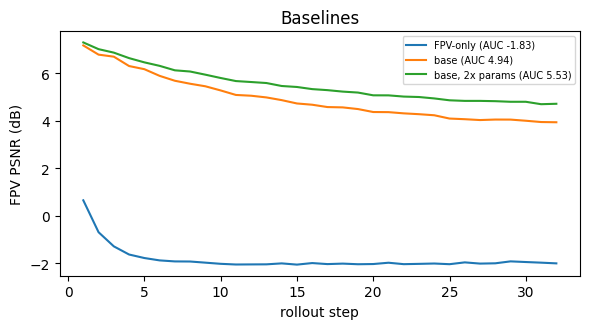

In [8]:
ALL = {}                                     # every strategy's results, for the summary in section 11
ALL.update(rollout({
    "FPV-only":     fpv_only_strategy(models["fpv_only"]),
    "base":         joint_strategy(models["base"]),
    "base, 2x params": joint_strategy(models["base_2x"]),
}))
report({k: ALL[k] for k in ("FPV-only", "base", "base, 2x params")}, no_ortho=("FPV-only",))
plot_psnr(ALL, ["FPV-only", "base", "base, 2x params"], "Baselines"); plt.tight_layout(); plt.show()

**How to read this** (numbers from the run saved in this notebook)

* **Seeing the ortho views helps a lot.** The FPV-only model is far below the others from step 1 (PSNR 0.66 vs. 7.18). FPV packs 96 numbers into 64, so FPV$_t$ alone can't tell the model where the state is. This is the toy version of the multi-view vs. FPV-only result.
* **The current ortho model drifts.** Its FPV PSNR falls from 7.18 dB at step 1 to 3.95 dB at step 32, and its ortho error grows about 10× (0.027 → 0.265).
* **Capacity alone helps** (AUC 4.94 → 5.53 with twice the parameters). Idea 4 uses two models, so section 9 compares it with this row, not with `base`.

## 5. Step 0: where does the drift come from?

Three questions decide which ideas can work. They're the same diagnostics proposed for the real model.

1. **Is FPV the harder view?** Compare each view's error relative to its own variance, per step. If FPV is much worse than the orthos, rendering FPV from the orthos (idea 4) can help.
2. **How much of the ortho error is the views disagreeing?** Split the error on each shared part into the part both copies agree on and the part where they disagree. Only the second part is visible to a cross-view check (ideas 1–3). An error the views agree on, a consistently wrong state, can't be voted out.
3. **Does disagreement now predict FPV error later?** If it did, a cross-view check would be a useful drift detector.

relative error (MSE / variance) of the current model, steps 1, 8, 16, 32
  FPV   [0.191, 0.277, 0.34, 0.403]
  ortho [0.027, 0.127, 0.197, 0.267]
share of the ortho error where the copies disagree, steps 1, 2, 4, 8, 16, 32
   [0.418, 0.263, 0.156, 0.095, 0.06, 0.045]
corr(disagreement at step 1, FPV error growth to step 2) = -0.025
corr(disagreement at step 4, FPV error growth to step 5) = -0.026
corr(disagreement at step 8, FPV error growth to step 9) = -0.035
corr(disagreement at step 16, FPV error growth to step 17) = +0.033


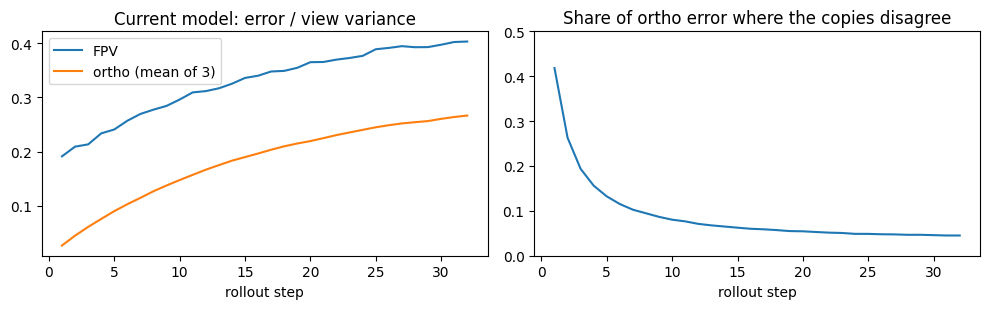

In [9]:
rb = ALL["base"]
ortho_var = render_views(EVAL_S0)[:, :, :3].var().item()
rel_fpv = rb["fpv"].mean(1).cpu() / rb["fpv_var"]
rel_ortho = rb["ortho"].mean(1).cpu() / ortho_var
split = torch.tensor(rb["split"])

print("relative error (MSE / variance) of the current model, steps 1, 8, 16, 32")
print("  FPV  ", [round(rel_fpv[i].item(), 3) for i in (0, 7, 15, 31)])
print("  ortho", [round(rel_ortho[i].item(), 3) for i in (0, 7, 15, 31)])
print("share of the ortho error where the copies disagree, steps 1, 2, 4, 8, 16, 32")
print("  ", [round(split[i].item(), 3) for i in (0, 1, 3, 7, 15, 31)])
for k in (1, 4, 8, 16):
    x, y = rb["disagree"][k - 1], rb["fpv"][k] - rb["fpv"][k - 1]
    print(f"corr(disagreement at step {k}, FPV error growth to step {k + 1}) = {torch.corrcoef(torch.stack([x, y]))[0, 1]:+.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
steps = range(1, T_ROLLOUT + 1)
ax[0].plot(steps, rel_fpv, label="FPV"); ax[0].plot(steps, rel_ortho, label="ortho (mean of 3)")
ax[0].set_title("Current model: error / view variance"); ax[0].set_xlabel("rollout step"); ax[0].legend()
ax[1].plot(steps, split); ax[1].set_ylim(0, 0.5)
ax[1].set_title("Share of ortho error where the copies disagree"); ax[1].set_xlabel("rollout step")
plt.tight_layout(); plt.show()

**How to read this**

* **FPV is the harder view.** At step 1 its relative error is 0.19, against 0.027 for the orthos. In this toy that's by construction (the $\tanh$ render); section 10 removes it.
* **Drift is mostly the views agreeing on a wrong state.** At step 1, 42% of the ortho error is disagreement between copies. By step 8 it's 9.5%, and by step 32 it's 4.5%. Each step, the model absorbs the disagreement it's given into a single, consistent but wrong state, and that is what accumulates.
* **Disagreement doesn't predict where the FPV goes next** (correlations around zero). In this toy, a cross-view check is a poor drift alarm.

So a cross-view check can only remove the error that exists *within* a single step, before the next step absorbs it. That is what idea 2 does. Idea 1 works on the next step's input, where `base` already averages the copies; idea 3 makes the views agree without averaging them. Both should do little.

## 6. Idea 1: train the model to outvote a bad view

`vote` was trained with one context view sometimes rendered from a perturbed state, and with independent noise levels per view (section 3). If the model learned to outvote such a view, its own disagreeing errors should be outvoted too when they come back as context.

In [10]:
ALL.update(rollout({
    "vote (1)":          joint_strategy(models["vote"]),
}))
report({k: ALL[k] for k in ("base", "vote (1)")})

strategy                          NFE | PSNR@1     @8    @16    @32    AUC | ortho@1 ortho@32 disagree@32
base                               20 |   7.18   5.57   4.68   3.95   4.94 |  0.0268   0.2654      0.0479
vote (1)                           20 |   7.13   5.48   4.61   3.82   4.85 |  0.0301   0.2737      0.0539


**How to read this**

* **No gain** (AUC 4.85 vs. 4.94).
* **`base` already does most of the voting.** Its context noise is drawn independently for each view (only the *level* is shared), so it already learns to average the copies it's given.
* **What's left to vote on is small.** As section 5 showed, most of the error that accumulates is the views agreeing on a wrong state.

## 7. Idea 2: repair the views every step

Make the views agree again *before* they're fed back, while there is still disagreement to remove.

* **Exact repair** replaces each shared part with the mean of its two copies. It needs to know exactly what the views share. In the toy that's trivial; in the games, two ortho views share only the extents along one axis. So this row is an upper bound for a geometry-based repair.
* **Consensus** needs no geometry. Re-noise all the predicted views to the sampling grid's last noise level ($\tau \approx 0.14$ on the 20-step shifted grid) and take that last Euler step again, with the same model and context. A denoiser trained on views that always agree pulls the copies toward each other, and it sees the context while doing it. This costs **one** extra model call, and it works on an existing checkpoint with no retraining. A row with a larger re-noise level ($\tau \approx 0.35$, 3 extra calls) checks whether more is better.

Both are applied to the current model here, and to the ortho-state model in section 9. The last two rows are a control: the FPV-only model has one view, so nothing to agree with. Whatever consensus does there is a plain sampler effect (one more denoising step), not a cross-view one.

In [11]:
ALL.update(rollout({
    "base + exact repair (2)":    joint_strategy(models["base"], "repair"),
    "base + consensus (2)":       joint_strategy(models["base"], "consensus"),
    "base + consensus, tau 0.35": joint_strategy(models["base"], "consensus", renoise=0.4),
    "base, 2x + exact repair":    joint_strategy(models["base_2x"], "repair"),
    "base, 2x + consensus":       joint_strategy(models["base_2x"], "consensus"),
    "FPV-only + consensus":       fpv_only_strategy(models["fpv_only"], "consensus"),
}))
report({k: ALL[k] for k in ("base", "base + exact repair (2)", "base + consensus (2)", "base + consensus, tau 0.35",
                            "base, 2x params", "base, 2x + exact repair", "base, 2x + consensus",
                            "FPV-only", "FPV-only + consensus")}, no_ortho=("FPV-only", "FPV-only + consensus"))

strategy                          NFE | PSNR@1     @8    @16    @32    AUC | ortho@1 ortho@32 disagree@32
base                               20 |   7.18   5.57   4.68   3.95   4.94 |  0.0268   0.2654      0.0479
base + exact repair (2)            20 |   7.25   5.79   5.03   4.40   5.25 |  0.0155   0.2153      0.0000
base + consensus (2)               21 |   7.58   5.95   5.05   4.32   5.29 |  0.0255   0.2469      0.0397
base + consensus, tau 0.35         23 |   7.41   5.60   4.67   3.97   4.94 |  0.0290   0.2785      0.0473
base, 2x params                    20 |   7.31   6.08   5.34   4.72   5.53 |  0.0189   0.1943      0.0337
base, 2x + exact repair            20 |   7.24   6.28   5.57   5.02   5.74 |  0.0113   0.1617      0.0000
base, 2x + consensus               21 |   7.67   6.40   5.65   5.08   5.87 |  0.0186   0.1821      0.0303
FPV-only                           20 |   0.66  -1.92  -1.98  -2.00  -1.83 |       -        -           -
FPV-only + consensus               21 |   0.82

**How to read this**

* **Exact repair helps at every model size.** AUC 4.94 → 5.25 for `base`, and 5.53 → 5.74 for `base_2x`.
* **Consensus gets similar FPV gains for one extra model call:** 5.29 and 5.87.
* **Most of the consensus gain isn't cross-view.**
  * On the FPV-only model, which has nothing to agree with, it also helps (AUC −1.83 → −1.59).
  * In section 9 it does nothing for the ortho-state model, whose FPV comes from the renderer.
  * So consensus works mainly as one more denoising step on whatever the model generates. Its cross-view part is the small cut in disagreement (0.048 → 0.040 at step 32).
* **More re-noising is not better** (4.94 at $\tau \approx 0.35$). The fresh noise adds new error faster than the extra steps remove it. Keep it to the last step.
* **On the real model, consensus is the cheapest experiment, but run it on both arms.** In `eval_longrollout.py`, after `predict_next_view_latents`, re-noise the latents to the grid's last level and run that Euler step again with the same context. It works on existing checkpoints. Because it is mostly a sampler gain, apply it to the FPV-only and the ortho checkpoints alike. Only the difference between the two gains is the ortho views' contribution.

## 8. Idea 3: leave-one-out refinement

After the joint draft, regenerate each view in turn from the other three with `tangle`'s leave-one-out conditional.

In [12]:
ALL.update(rollout({
    "tangle":              joint_strategy(models["tangle"]),
    "tangle + refine (3)": joint_strategy(models["tangle"], "refine"),
}))
report({k: ALL[k] for k in ("base", "tangle", "tangle + refine (3)")})

strategy                          NFE | PSNR@1     @8    @16    @32    AUC | ortho@1 ortho@32 disagree@32
base                               20 |   7.18   5.57   4.68   3.95   4.94 |  0.0268   0.2654      0.0479
tangle                             20 |   7.18   5.31   4.37   3.51   4.60 |  0.0303   0.3124      0.0532
tangle + refine (3)               100 |   7.12   5.37   4.35   3.54   4.61 |  0.0306   0.3125      0.0532


**How to read this**

* **No gain, at 5× the model calls** (AUC 4.61 vs. 4.60 without refinement, and 4.94 for `base`).
* **The sweep copies instead of averaging.** Regenerating Top from Side and Rear sets Top's copy of $a$ to Side's copy, and its copy of $b$ to Rear's. The views end up agreeing, but on one copy's error rather than the average of two. So the total error doesn't go down. Section 7's repair averages, which is why it helps and this doesn't.
* **`tangle` alone is already a bit below `base`** (4.60 vs. 4.94): leave-one-out training costs the joint task half its batches.

## 9. Idea 4: the ortho views as the state

Split the world model in two:

* **Dynamics** (`ortho_dyn`): Top, Side, Rear at $t$, plus the action → Top, Side, Rear at $t+1$. It never sees FPV.
* **Render** (`renderer`): Top, Side, Rear at $t+1$ → FPV$_{t+1}$.

At every step, the FPV is rendered fresh from the predicted orthos and is never fed back. FPV errors can't compound, and the dynamics don't spend capacity on the hardest view. This costs two models and twice the model calls. The fair comparison is therefore `base, 2x params`, which has as many parameters as the two together.

Also shown: the current model with only its FPV replaced by the renderer's (`base + re-render FPV`). It separates the gain from a better FPV render from the gain from keeping FPV out of the dynamics.

strategy                          NFE | PSNR@1     @8    @16    @32    AUC | ortho@1 ortho@32 disagree@32
base                               20 |   7.18   5.57   4.68   3.95   4.94 |  0.0268   0.2654      0.0479
base, 2x params                    20 |   7.31   6.08   5.34   4.72   5.53 |  0.0189   0.1943      0.0337
base + re-render FPV               40 |   8.31   6.09   4.88   4.17   5.33 |  0.0268   0.2685      0.0473
ortho state (4)                    40 |   8.45   6.65   5.63   4.79   5.93 |  0.0195   0.2098      0.0340
ortho state + repair (2+4)         40 |   8.48   6.98   6.02   5.36   6.32 |  0.0118   0.1642      0.0000
ortho state + consensus (2+4)      41 |   8.46   6.61   5.63   4.86   5.93 |  0.0193   0.2031      0.0296


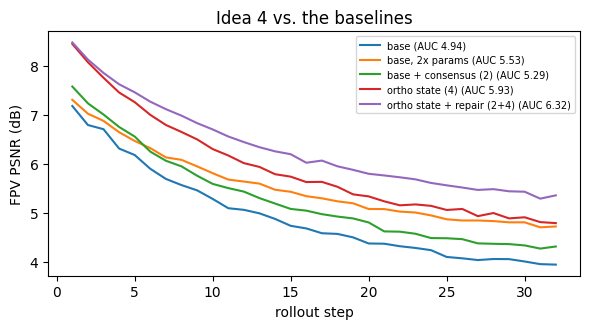

In [13]:
ALL.update(rollout({
    "base + re-render FPV":      joint_strategy(models["base"], "rerender", renderer=models["renderer"]),
    "ortho state (4)":           ortho_state_strategy(models["ortho_dyn"], models["renderer"]),
    "ortho state + repair (2+4)": ortho_state_strategy(models["ortho_dyn"], models["renderer"], "repair"),
    "ortho state + consensus (2+4)": ortho_state_strategy(models["ortho_dyn"], models["renderer"], "consensus"),
}))
report({k: ALL[k] for k in ("base", "base, 2x params", "base + re-render FPV", "ortho state (4)",
                            "ortho state + repair (2+4)", "ortho state + consensus (2+4)")})
plot_psnr(ALL, ["base", "base, 2x params", "base + consensus (2)", "ortho state (4)", "ortho state + repair (2+4)"],
          "Idea 4 vs. the baselines"); plt.tight_layout(); plt.show()

**How to read this**

* **Ortho state beats the capacity-matched baseline:** AUC 5.93 vs. 5.53.
* **The gain comes from a better FPV render, not from slower drift.**
  * It's front-loaded: 8.45 vs. 7.31 dB at step 1, but 4.79 vs. 4.72 at step 32.
  * The dedicated renderer is more accurate than the joint model's FPV. `base + re-render FPV` alone lifts step 1 from 7.18 to 8.31.
  * Once the state has drifted, a better render of a wrong state doesn't help much.
* **Keeping FPV out of the dynamics lets a smaller model match a bigger one.** `ortho_dyn` (3.3M parameters) has about the ortho error of `base_2x` (6.4M): 0.020 vs. 0.019 at step 1, and 0.210 vs. 0.194 at step 32. `base`, at the same size as `ortho_dyn`, is at 0.027 and 0.265.
* **Exact repair stacks on top: 6.32, the best of anything in this notebook** (+0.79 dB over `base_2x`, +1.38 over `base`).
* **Consensus doesn't stack (5.93).** The FPV comes from the renderer, so the extra denoising step has no FPV to clean up.
* **The catch:** all of this relies on FPV being the harder view (section 5). The next section checks what happens when it isn't.

## 10. When does idea 4 help? A world with an easy FPV

The same toy with FPV $= R s$ (no $\tanh$): FPV is now as easy to predict as the ortho views. `base`, `base_2x`, `ortho_dyn` and `renderer` are retrained in this world, with the same budget and seed, and evaluated on the same trajectories.

In [14]:
FPV_MODE = "linear"
t0 = time.time()
lin = {}
for name, fn, layers in (("base", loss_base, 4), ("base_2x", loss_base, 8),
                         ("ortho_dyn", loss_ortho_dyn, 4), ("renderer", loss_renderer, 4)):
    lin[name] = train(fn, layers=layers)
    print(f"trained {name:10s} ({time.time() - t0:.0f}s)")
LIN = rollout({
    "base":                   joint_strategy(lin["base"]),
    "base + consensus (2)":   joint_strategy(lin["base"], "consensus"),
    "base + exact repair (2)": joint_strategy(lin["base"], "repair"),
    "base, 2x params":        joint_strategy(lin["base_2x"]),
    "base, 2x + exact repair": joint_strategy(lin["base_2x"], "repair"),
    "ortho state (4)":        ortho_state_strategy(lin["ortho_dyn"], lin["renderer"]),
    "ortho state + repair (2+4)": ortho_state_strategy(lin["ortho_dyn"], lin["renderer"], "repair"),
})
report(LIN)
FPV_MODE = "tanh"

trained base       (65s)


trained base_2x    (193s)


trained ortho_dyn  (249s)


trained renderer   (290s)


strategy                          NFE | PSNR@1     @8    @16    @32    AUC | ortho@1 ortho@32 disagree@32
base                               20 |  16.26   9.20   7.21   5.82   8.09 |  0.0250   0.2624      0.0482
base + consensus (2)               21 |  16.46   9.49   7.55   6.22   8.39 |  0.0242   0.2418      0.0413
base + exact repair (2)            20 |  16.28   9.87   7.89   6.56   8.73 |  0.0143   0.2089      0.0000
base, 2x params                    20 |  17.38  10.37   8.37   6.99   9.25 |  0.0183   0.2006      0.0324
base, 2x + exact repair            20 |  17.39  10.81   8.88   7.38   9.67 |  0.0109   0.1753      0.0000
ortho state (4)                    40 |  16.28   9.45   7.45   6.00   8.32 |  0.0197   0.2371      0.0349
ortho state + repair (2+4)         40 |  16.48  10.19   8.25   6.75   9.02 |  0.0115   0.1900      0.0000


**How to read this**

* **With an easy FPV, ortho state loses to the capacity-matched baseline.** AUC 8.32 vs. 9.25 for `base_2x`, and 16.28 vs. 17.38 dB at step 1. The renderer adds its own error on top of the ortho error, and there is nothing hard to take off the dynamics model.
* **Repair still helps every model:** `base` 8.09 → 8.73, `base_2x` 9.25 → 9.67, ortho state 8.32 → 9.02. Consensus: 8.09 → 8.39.

So idea 4 depends on FPV being harder to predict than the ortho views. Section 5's first diagnostic answers that on the real model.

## 11. Summary, and what to run on the real model

In [15]:
order = ["FPV-only", "base", "base, 2x params", "vote (1)", "base + exact repair (2)", "base + consensus (2)",
         "tangle + refine (3)", "base + re-render FPV", "ortho state (4)", "ortho state + repair (2+4)",
         "ortho state + consensus (2+4)"]
report({k: ALL[k] for k in order}, no_ortho=("FPV-only",))

strategy                          NFE | PSNR@1     @8    @16    @32    AUC | ortho@1 ortho@32 disagree@32
FPV-only                           20 |   0.66  -1.92  -1.98  -2.00  -1.83 |       -        -           -
base                               20 |   7.18   5.57   4.68   3.95   4.94 |  0.0268   0.2654      0.0479
base, 2x params                    20 |   7.31   6.08   5.34   4.72   5.53 |  0.0189   0.1943      0.0337
vote (1)                           20 |   7.13   5.48   4.61   3.82   4.85 |  0.0301   0.2737      0.0539
base + exact repair (2)            20 |   7.25   5.79   5.03   4.40   5.25 |  0.0155   0.2153      0.0000
base + consensus (2)               21 |   7.58   5.95   5.05   4.32   5.29 |  0.0255   0.2469      0.0397
tangle + refine (3)               100 |   7.12   5.37   4.35   3.54   4.61 |  0.0306   0.3125      0.0532
base + re-render FPV               40 |   8.31   6.09   4.88   4.17   5.33 |  0.0268   0.2685      0.0473
ortho state (4)                    40 |   8.45

**What the toy says** (one seed; the tanh world unless noted)

| idea | effect on rollout PSNR (AUC) | why | real-model cost |
|---|---|---|---|
| 1. vote | none (4.85 vs. 4.94) | `base` already averages the copies in its context; most drift is consistent | a training flag |
| 2. exact repair | **+0.2 to +0.7 dB**, at every model size and in both worlds | removes disagreement before the next step absorbs it | needs an exact cross-view constraint, which the games only partly give |
| 2. consensus: redo the last step | +0.3 dB on the multi-view models, but also +0.24 on FPV-only, and 0 on ortho state | mostly one more denoising step, not cross-view | **1 extra NFE, no retraining** |
| 3. leave-one-out refine | none, at 5× NFE | the sweep copies one view's error instead of averaging | tangle training + 4× NFE |
| 4. ortho state + renderer | **+0.4 dB** over the capacity-matched model, from a better render (tied at step 32); **−0.9 dB with an easy FPV** | the dynamics skip the hard view; a dedicated model renders it | two models (or LoRAs), 2× NFE |
| 4 + exact repair | **+0.8 dB** over the capacity-matched model, the best here | both of the above | as above, plus the constraint |

**What to run on the real model, in order**

1. **The step-0 diagnostics on Wan.** They decide which of the rest is worth doing.
   * Log per-step PSNR for each view, not only FPV, and compare the views' step-1 errors relative to each other.
   * If FPV is much worse than the orthos, idea 4 is worth the effort. If not, it will likely hurt, as in section 10.
   * For disagreement, a projector trained on ground truth to map the three ortho views to the FPV, such as `LinearProjector` in `train_ortho_project.py`, can stand in for the known geometry. Compare its projection of the generated orthos with the generated FPV, per step.
2. **Consensus re-denoise in `eval_longrollout.py`.** No training needed.
   * After `predict_next_view_latents`, re-noise the predicted latents to the grid's last noise level and run that Euler step again with the same context, before decoding and re-encoding them as the next state.
   * Run it on the FPV-only *and* the ortho checkpoints. Expect a sampler gain on both; only the difference between the two is due to the ortho views.
3. **If FPV is the harder view: ortho state + renderer.**
   * The dynamics are one more entry in `ARMS`: `{"context": (0, 1, 2), "targets": (0, 1, 2), "memory": False}`, one LoRA.
   * The renderer is a second LoRA: Top, Side, Rear at $t+1$, plus FPV$_t$ and the camera pose → FPV$_{t+1}$.
   * In the games, keep FPV$_t$ in the renderer's context. Unlike in this toy, the FPV shows content the ortho crops don't (background, horizon, far objects), and it depends on the orbiting camera's pose. FPV errors then feed back into the renderer, but never into the dynamics.
4. **A real cross-view repair is a research step, not a flag.** The toy's exact repair averages parts the views share exactly. In the games, two ortho views share only their extents along one axis. The nearest analog is pushing the shared-axis silhouettes into agreement, for example with HiFi's object masks, as a training loss or as guidance during sampling. The toy's +0.2 to +0.8 dB is an upper bound for that.
5. **Skip ideas 1 and 3** unless the real model's disagreement share (diagnostic 1) stays high deep into the rollout.

These all sit on top of the general exposure-bias fixes, which the toy doesn't model: training contexts that look like inference contexts, the VAE round-trip, and context noise at inference.